# 09. 실험 4c — 모델의 "틀리는 버릇" 빼기 (라벨 없이)

**한 줄 요약:** 사진(위성 값)을 고치지 않는다. 대신 모델이 **처음 보는 지역에서 무엇을 무엇으로 착각하는지**(버릇)를 다른 지역들에서 재 두고, 새 지역의 예측 **비율**에서 그 버릇을 거꾸로 빼서 탄소 합계를 고친다. 새 지역의 라벨은 쓰지 않는다.

**쉬운 설명**
- 지금까지(실험 3·4a·4b): 모델이 보는 사진을 고침 → 정답을 줘도 안 됨(4b)
- 이번: 체중계를 뜯지 않고, "늘 1kg 더 나온다"는 버릇을 알아서 결과에서 뺀다
- 버릇 = 혼동표(침엽을 활엽으로 몇 %, 활엽을 혼효로 몇 % … 착각하는지)
- α = 버릇을 얼마나 빼 줄지 (0 = 안 뺌, 1 = 다 뺌)

**비교하는 것**

| 이름 | 방법 | 라벨 |
|---|---|---|
| α=0 | 그냥 예측 (05와 같음) | 없음 |
| 상수 보정 | 다른 7곳의 평균 탄소 오차만큼 뺌 (가장 단순한 버릇 빼기, 기준선) | 다른 지역 결과만 |
| **혼동표 보정 (판정)** | 다른 7곳의 혼동표 평균으로 예측 비율을 거꾸로 풀어 비율을 고침 | 다른 지역 결과만 |
| EM (기록만) | 모델 확률만으로 지역 비율을 반복 추정 | 없음 |

**왜 RF를 다시 돌리나:** 05·08은 탄소 합계와 F1만 저장해서 혼동표가 없다. 이번에는 폴드마다 **혼동표와 픽셀별 확률을 저장**해 둔다(다음에 다른 비율 보정을 시험할 때 재학습 불필요).

**순서:** [1] 설정 → [2] 사전 기록(확정 전엔 멈춤) → [3] 함수 → [4] 읽기·검산 → [5] LORO 40폴드(약 1.5–2시간 [추정], 폴드 단위 저장) → [6] 모으기·보정 계산 → [7] 진단 → [8] 주 결과 → [9] 사전 기록과 대조 → [10] 기록만 → [11] 그림·저장

**끊겼을 때:** `모두 실행` 다시. 끝난 폴드는 건너뛴다. 원본 수정 없음.

In [14]:
# [1] 설정 — 05 [1]·08 [1]과 같은 경로·지역·계수·RF·표본 수
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
from scipy.optimize import nnls
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
OUT      = '/content/drive/MyDrive/forest/outputs'
FOLD_DIR = f'{OUT}/exp4c_folds'
os.makedirs(FOLD_DIR, exist_ok=True)

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
LAT = {'inje': 38.04, 'hongcheon': 37.75, 'gangneung': 37.71, 'pyeongchang': 37.54,
       'bonghwa': 36.92, 'geumsan': 36.13, 'geochang': 35.71, 'suncheon': 35.01}

C    = {1: 79.25, 2: 101.02, 3: 92.01}           # 확정계수. 구계수 사용 금지
CVEC = np.array([C[1], C[2], C[3]])
SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000                      # 05와 동일
RF_PARAMS = dict(n_estimators=80, min_samples_leaf=20, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1)   # 05와 동일
ALPHAS_REC = [0.0, 0.25, 0.5, 0.75, 1.0]         # 보정 세기 스윕 (기록만)

for r in TRAIN_REGIONS:
    assert os.path.exists(f'{OUT}/{r}_s05.npz'), f'05 캐시 없음: {r}'
    for s in SEEDS:
        assert os.path.exists(f'{OUT}/exp2_folds/s{s}_{r}.npz'), f'05 폴드 파일 없음: s{s}_{r} (재현 검산용)'
print('CPU 코어:', os.cpu_count(), '/ 05 캐시·폴드 파일 확인 완료')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CPU 코어: 2 / 05 캐시·폴드 파일 확인 완료


## 실험 4c 사전 기록 — 결과를 보기 전에 확정

**읽어 보고 맞으면 [2]의 `CONFIRMED = True`로 바꾼 뒤 실행.**

| 항목 | 내용 (쉬운 말) |
|---|---|
| 설계 | 05와 똑같은 LORO 40폴드(같은 학습 표본·같은 RF·같은 시드). α=0 결과가 05와 똑같은지 폴드마다 확인 |
| 판정 방법 | **혼동표 보정, α = 1 고정** (버릇을 다 뺌). 지역 r의 혼동표 = 같은 시드에서 **나머지 7곳 폴드의 혼동표(행 비율) 평균**. r의 라벨은 안 씀 |
| 누설 (간이 방식) | 나머지 7곳 폴드의 모델은 r을 학습에 썼다 → 실험 3처럼 낙관 쪽으로 치우칠 수 있음. 엄밀 방식(안쪽 LORO)은 7배 시간이라 안 함 |
| A. 보정 효과 | 시드마다 \|오차\|가 α=0보다 줄어든 지역 **6/8 이상** AND 평균 개선 **0.1%p 초과** (실험 3·4b와 같은 기준) |
| B. 기준선보다 나음 | 5시드 평균 지역 \|오차\|: 혼동표 보정 **<** 상수 보정 |
| 통과 | A가 **5/5 시드** AND B |
| F1 | 판정에서 뺌 — 픽셀 예측을 바꾸지 않으므로 F1은 α=0과 같다 |
| 사전 예측 [추정] | 지역 \|오차\| 평균 1.1–1.3%, 줄어든 지역 시드당 4–5/8 → **A는 실패할 가능성이 큼**. 강릉·순천(오차 −)·거창(+0.38로 작음)은 공통 버릇과 방향이 달라 안 고쳐지거나 나빠짐 |
| 통과하면 | 라벨 없는 "버릇 빼기" 유효 → 새 지역(사후 추가)에서 확인 |
| 실패하면 | 실패 먼저 보고. [7] 진단으로 "지역마다 다른 착각"이 무엇인지 정리 → 지역별 버릇을 잡는 방법(혼합 틀 맞추기)을 시도할지, 여기서 정리할지 결정 |
| 기록만 | α 스윕(0–1), 상수 보정, EM, 진단 표(실제 vs 예측 비율), 면적가중 합산 |

한 번 저장된 `exp4c_prereg.json`은 덮어쓰지 않는다.

In [15]:
# [2] 사전 기록 — 확정 전에는 여기서 멈춘다 (정상 정지)
CONFIRMED = True   # ← 위 표를 읽고 맞으면 True로 바꾼다

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'seen_before_prereg': ('실험 2·3·4a·4b 결과 전체. 상수 보정은 채팅에서 exp2 5시드 평균 오차로 미리 계산해 봄 '
                           '(지역 |오차| 평균 1.38→1.27%, 줄어든 지역 5/8). 혼동표·확률·EM 결과는 본 적 없음'),
    'purpose': '라벨 없이 모델의 공통 착각(혼동표)을 예측 비율에서 빼면 지역 탄소 오차가 줄어드는가',
    'design': ('05 [7]과 같은 LORO 40폴드: 같은 학습 표본(rng=default_rng(seed), 지역당 30,000), 같은 RF(random_state=seed). '
               'α=0이 05 폴드 파일과 0.01%p 이내 일치하는지 폴드마다 assert'),
    'method_judged': ('혼동표 보정(ACC), α=1. M_r = 같은 시드 나머지 7지역 폴드의 혼동표(행 = 실제, 행 합 1) 단순 평균. '
                      '예측 비율 q에 대해 q ≈ M_rᵀ π 를 π ≥ 0, Σπ = 1 로 풂(nnls). 탄소 = n × Σ π·C. '
                      'α 보정 비율 = (1−α)·q + α·π'),
    'leakage': '간이 방식: M_r을 만든 모델들은 r을 학습에 포함 → 낙관 쪽 치우침 가능. 엄밀(안쪽 LORO, 약 7배 시간)은 하지 않음',
    'criteria': {
        'A': '시드마다: |오차|가 α=0보다 줄어든 지역 >= 6/8 AND 평균 개선(|e0|-|e_acc|) > 0.1 %p',
        'B': '5시드 평균 지역 |오차|: 혼동표 보정 < 상수 보정',
        'pass': 'A 5/5 시드 AND B',
    },
    'baseline_const': '상수 보정: e_r − (같은 시드 나머지 7지역 α=0 오차의 평균). 탄소 % 단위에서 바로 뺌',
    'f1': '판정 제외 (픽셀 예측 불변)',
    'prediction': ('[추정] 지역 |오차| 평균 1.1–1.3%, 줄어든 지역 시드당 4–5/8 → A 실패 가능성 큼. '
                   '강릉·순천(α=0 오차 음수)과 거창(+0.38)은 안 고쳐지거나 나빠짐'),
    'if_pass': '라벨 없는 버릇 빼기 유효 → 새 지역(사후 추가 표시)에서 확인',
    'if_fail': '실패 먼저 보고 → [7] 진단으로 지역별로 다른 착각 정리 → 지역별 버릇 방법(혼합 틀 맞추기) 시도 또는 정리 결정',
    'record_only': ['α 스윕 0/0.25/0.5/0.75/1', '상수 보정', 'EM(Saerens 2002, 학습 쪽 사전확률 = 균등, class_weight=balanced 때문)',
                    '진단: 지역별 실제 vs 예측 클래스 비율과 탄소 오차 기여', '면적가중 합산'],
    'saved_for_later': '폴드별 혼동표(개수), 예측 비율, 픽셀별 확률(float16)',
    'carbon_coeff': C,
    'rf': {k: v for k, v in RF_PARAMS.items() if k != 'n_jobs'},
    'references': ['Forman 2008, Data Min Knowl Disc 17:164 — Adjusted Classify & Count',
                   'Saerens et al. 2002, Neural Comput 14:21 — EM prior adjustment'],
    'failure_report': '통과 못 하면 실패라고 먼저 쓴다. 기준을 결과 보고 바꾸지 않는다',
}

PRE = f'{OUT}/exp4c_prereg.json'
if os.path.exists(PRE):
    print('이미 저장된 사전 기록을 사용 (덮어쓰지 않음):', PRE)
else:
    assert CONFIRMED, '사전 기록을 읽고 CONFIRMED = True로 바꾼 뒤 다시 실행 (정상 정지)'
    json.dump(PREREG, open(PRE, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    print('사전 기록 저장:', PRE)
print(json.dumps(json.load(open(PRE, encoding='utf-8')), ensure_ascii=False, indent=2))

이미 저장된 사전 기록을 사용 (덮어쓰지 않음): /content/drive/MyDrive/forest/outputs/exp4c_prereg.json
{
  "date": "2026-10-03 09:53",
  "seen_before_prereg": "실험 2·3·4a·4b 결과 전체. 상수 보정은 채팅에서 exp2 5시드 평균 오차로 미리 계산해 봄 (지역 |오차| 평균 1.38→1.27%, 줄어든 지역 5/8). 혼동표·확률·EM 결과는 본 적 없음",
  "purpose": "라벨 없이 모델의 공통 착각(혼동표)을 예측 비율에서 빼면 지역 탄소 오차가 줄어드는가",
  "design": "05 [7]과 같은 LORO 40폴드: 같은 학습 표본(rng=default_rng(seed), 지역당 30,000), 같은 RF(random_state=seed). α=0이 05 폴드 파일과 0.01%p 이내 일치하는지 폴드마다 assert",
  "method_judged": "혼동표 보정(ACC), α=1. M_r = 같은 시드 나머지 7지역 폴드의 혼동표(행 = 실제, 행 합 1) 단순 평균. 예측 비율 q에 대해 q ≈ M_rᵀ π 를 π ≥ 0, Σπ = 1 로 풂(nnls). 탄소 = n × Σ π·C. α 보정 비율 = (1−α)·q + α·π",
  "leakage": "간이 방식: M_r을 만든 모델들은 r을 학습에 포함 → 낙관 쪽 치우침 가능. 엄밀(안쪽 LORO, 약 7배 시간)은 하지 않음",
  "criteria": {
    "A": "시드마다: |오차|가 α=0보다 줄어든 지역 >= 6/8 AND 평균 개선(|e0|-|e_acc|) > 0.1 %p",
    "B": "5시드 평균 지역 |오차|: 혼동표 보정 < 상수 보정",
    "pass": "A 5/5 시드 AND B"
  },
  "baseline_const": "상수 보정: e_r − (같은 시드 나머지 7지역 α=0 오차의 평균). 탄소 % 단위에서 바로 뺌",
  "f1": 

In [16]:
# [3] 함수 — carbon_sum은 05 [3] 원본. 나머지는 비율 보정용
def carbon_sum(y):
    return float(sum((y == v).sum() * C[v] for v in (1, 2, 3)))

def carbon_from_props(props, n):
    # 비율(침엽·활엽·혼효) × 픽셀 수 × 계수
    return float(n * (np.asarray(props) @ CVEC))

def row_norm(cm):
    # 혼동표(행 = 실제, 열 = 예측) → 행 합 1. 빈 행은 단위행렬 행으로
    cm = np.asarray(cm, float)
    s = cm.sum(1, keepdims=True)
    out = np.where(s > 0, cm / np.where(s > 0, s, 1), np.eye(cm.shape[0]))
    return out

def acc_solve(M, q, w=1e3):
    # q ≈ Mᵀ π, π ≥ 0, Σπ = 1 (합 조건은 큰 가중치 행으로)
    A = np.vstack([M.T, w * np.ones(M.shape[0])])
    b = np.append(q, w)
    pi, _ = nnls(A, b)
    return pi / pi.sum()

def em_prior(P, prior_s, iters=200, tol=1e-7):
    # Saerens et al. 2002: 확률 P(n×K)와 학습 쪽 사전확률로 대상 지역 비율 추정 (라벨 없음)
    P = P.astype('float64')
    pi = prior_s.copy()
    for _ in range(iters):
        W = P * (pi / prior_s)
        W /= W.sum(1, keepdims=True)
        new = W.mean(0)
        if np.abs(new - pi).max() < tol:
            pi = new; break
        pi = new
    return pi

# 함수 자체 검산 (가짜 숫자, 1초 미만)
_rng = np.random.default_rng(0)
_M = row_norm(np.eye(3) * 6 + _rng.random((3, 3)))
_pi = np.array([0.5, 0.3, 0.2])
assert np.abs(acc_solve(_M, _M.T @ _pi) - _pi).max() < 1e-6
assert np.abs(acc_solve(np.eye(3), _pi) - _pi).max() < 1e-9
assert np.allclose(em_prior(np.tile(_pi, (10, 1)), _pi), _pi)
print('함수 정의·검산 완료')

함수 정의·검산 완료


In [17]:
# [4] 캐시 읽기 + 검산 (08 [4]와 같은 기준값)
assert os.path.exists(f'{OUT}/exp4c_prereg.json'), '[2] 사전 기록을 먼저 확정 (정상 정지)'
t0 = time.time()
S = {}
for r in TRAIN_REGIONS:
    z = np.load(f'{OUT}/{r}_s05.npz')
    S[r] = dict(X=z['X'], y=z['y'], n_total=int(z['n_total']))
    del z
print(f'캐시 읽기 {time.time()-t0:.0f}초, RAM {sum(S[r]["X"].nbytes for r in TRAIN_REGIONS)/1e6:.0f} MB')

N_REF = {'inje': 600263, 'hongcheon': 599525, 'gangneung': 600079, 'pyeongchang': 600530,
         'bonghwa': 599540, 'geumsan': 600247, 'geochang': 601114, 'suncheon': 600845}
W_REF = {'inje': 0.460, 'hongcheon': 0.418, 'gangneung': 0.536, 'pyeongchang': 0.378,
         'bonghwa': 0.632, 'geumsan': 0.456, 'geochang': 0.623, 'suncheon': 0.657}
for r in TRAIN_REGIONS:
    assert len(S[r]['y']) == N_REF[r] and S[r]['X'].shape[1] == 38, r
    assert abs(np.median(S[r]['X'][:, 21]) - W_REF[r]) < 0.0015, r
    assert set(np.unique(S[r]['y'])) <= {1, 2, 3}, r
print('검산 통과: 캐시 8곳 05와 일치 (표본 수, 피처 38, w_ndvi 중앙값, 클래스 1–3)')

캐시 읽기 17초, RAM 730 MB
검산 통과: 캐시 8곳 05와 일치 (표본 수, 피처 38, w_ndvi 중앙값, 클래스 1–3)


In [18]:
# [5] LORO 40폴드 — 폴드마다 저장. 끊기면 다시 실행하면 남은 폴드만
#   예측 1회/폴드(확률). 확률의 최댓값 클래스 = RF predict와 같음 → α=0이 05와 같아야 함
folds = [(s, r) for s in SEEDS for r in TRAIN_REGIONS]
todo  = [(s, r) for s, r in folds if not os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz')]
print(f'전체 {len(folds)}폴드 중 완료 {len(folds) - len(todo)}, 남은 {len(todo)}')
print('예상 [추정]: 05 실측 폴드당 169–179초(예측 7회) → 이번 예측 1회라 폴드당 약 2–2.5분, 40폴드 약 1.5–2시간. 첫 폴드 후 다시 계산해 출력\n')

times = []
for k, (seed, test) in enumerate(todo, 1):
    t0  = time.time()
    rng = np.random.default_rng(seed)                       # 05 [7]과 같은 표본 추출
    Xtr, ytr = [], []
    for r in TRAIN_REGIONS:
        if r == test: continue
        n = len(S[r]['y'])
        i = rng.choice(n, size=min(N_TRAIN_PER_REGION, n), replace=False)
        Xtr.append(S[r]['X'][i]); ytr.append(S[r]['y'][i])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr)
    prior_train = np.array([(ytr == v).mean() for v in (1, 2, 3)])

    clf = RandomForestClassifier(random_state=seed, **RF_PARAMS)
    clf.fit(Xtr, ytr)
    del Xtr, ytr; gc.collect()
    assert list(clf.classes_) == [1, 2, 3], clf.classes_

    Xb, yb = S[test]['X'], S[test]['y']
    P = clf.predict_proba(Xb)                                 # (n, 3) float64
    p = clf.classes_[P.argmax(1)]
    del clf; gc.collect()

    t_c = carbon_sum(yb)
    e0  = (carbon_sum(p) - t_c) * 100 / t_c
    ref = float(np.load(f'{OUT}/exp2_folds/s{seed}_{test}.npz')['carb'][0])
    assert abs(e0 - ref) < 0.01, f's{seed} {test}: α=0 오차 {e0:.4f} ≠ 05의 {ref:.4f} — 여기서 멈추고 원인 확인'

    cm     = confusion_matrix(yb, p, labels=[1, 2, 3])        # 행 = 실제, 열 = 예측 (개수)
    q      = np.array([(p == v).mean() for v in (1, 2, 3)])   # 예측 비율
    truep  = np.array([(yb == v).mean() for v in (1, 2, 3)])  # 실제 비율 (진단용, 보정에 안 씀)
    pi_em  = em_prior(P, np.ones(3) / 3)                      # balanced → 학습 쪽 사전확률 균등

    np.savez_compressed(f'{FOLD_DIR}/s{seed}_{test}.npz',
             cm=cm, q=q, true_p=truep, pi_em=pi_em, prior_train=prior_train,
             proba=P.astype('float16'), carb0=e0, t_c=t_c, n_test=len(yb), n_total=S[test]['n_total'])
    del P, p; gc.collect()

    dt = time.time() - t0; times.append(dt)
    eta = np.mean(times) * (len(todo) - k) / 60
    print(f'[{k:2d}/{len(todo)}] s{seed} {test:12s} α=0 {e0:+6.2f}% (05와 일치)  '
          f'예측비율 {q.round(3)} / 실제 {truep.round(3)}   {dt:4.0f}초  남은 약 {eta:.0f}분')
print('\n모든 폴드 완료')

전체 40폴드 중 완료 40, 남은 0
예상 [추정]: 05 실측 폴드당 169–179초(예측 7회) → 이번 예측 1회라 폴드당 약 2–2.5분, 40폴드 약 1.5–2시간. 첫 폴드 후 다시 계산해 출력


모든 폴드 완료


In [19]:
# [6] 모으기 + 보정 계산 → exp4c_results.npz
ns, nr = len(SEEDS), len(TRAIN_REGIONS)
CM = np.full((ns, nr, 3, 3), np.nan); Q = np.full((ns, nr, 3), np.nan); TP = np.full_like(Q, np.nan)
PIEM = np.full_like(Q, np.nan); E0 = np.full((ns, nr), np.nan); TC = np.full_like(E0, np.nan); NT = np.full_like(E0, np.nan)
NTOT = np.array([S[r]['n_total'] for r in TRAIN_REGIONS], float)
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        z = np.load(f'{FOLD_DIR}/s{s}_{r}.npz')
        CM[i, j], Q[i, j], TP[i, j], PIEM[i, j] = z['cm'], z['q'], z['true_p'], z['pi_em']
        E0[i, j], TC[i, j], NT[i, j] = z['carb0'], z['t_c'], z['n_test']
assert not np.isnan(E0).any(), '미완료 폴드 있음 — [5]를 다시 실행'

def err_from_props(props, i, j):
    return (carbon_from_props(props, NT[i, j]) - TC[i, j]) * 100 / TC[i, j]

# 검산: 예측 비율로 계산한 탄소 = 픽셀 합으로 계산한 α=0
for i in range(ns):
    for j in range(nr):
        assert abs(err_from_props(Q[i, j], i, j) - E0[i, j]) < 1e-6
print('검산: 비율 → 탄소 계산이 α=0 오차와 일치')

# 혼동표 보정 (판정: α=1) + α 스윕
PI_ACC = np.full_like(Q, np.nan)
EA = np.full((ns, nr, len(ALPHAS_REC)), np.nan)
for i in range(ns):
    for j in range(nr):
        others = [k for k in range(nr) if k != j]
        M = np.mean([row_norm(CM[i, k]) for k in others], axis=0)      # r의 라벨 안 씀
        PI_ACC[i, j] = acc_solve(M, Q[i, j])
        for a_i, a in enumerate(ALPHAS_REC):
            EA[i, j, a_i] = err_from_props((1 - a) * Q[i, j] + a * PI_ACC[i, j], i, j)
jA = ALPHAS_REC.index(1.0)
E_ACC = EA[:, :, jA]
assert np.allclose(EA[:, :, 0], E0)

# 상수 보정 (기준선)
E_CONST = np.array([[E0[i, j] - np.mean([E0[i, k] for k in range(nr) if k != j]) for j in range(nr)] for i in range(ns)])

# EM (기록만)
E_EM = np.array([[err_from_props(PIEM[i, j], i, j) for j in range(nr)] for i in range(ns)])

np.savez(f'{OUT}/exp4c_results.npz', cm=CM, q=Q, true_p=TP, pi_acc=PI_ACC, pi_em=PIEM,
         e0=E0, e_acc=E_ACC, e_acc_sweep=EA, e_const=E_CONST, e_em=E_EM, t_c=TC, n_test=NT, n_total=NTOT,
         seeds=np.array(SEEDS), regions=np.array(TRAIN_REGIONS), alphas=np.array(ALPHAS_REC))
print('저장: exp4c_results.npz')

검산: 비율 → 탄소 계산이 α=0 오차와 일치
저장: exp4c_results.npz


In [20]:
# [7] 진단 — 지역마다 실제 비율 vs 예측 비율 (5시드 평균, %)
#   탄소 기여 = (예측 비율 − 실제 비율) × 계수 / 실제 평균 계수 → 합하면 α=0 탄소 오차
cls = ['침엽', '활엽', '혼효']
rows = []
for j, r in enumerate(TRAIN_REGIONS):
    tp, q = TP[:, j].mean(0), Q[:, j].mean(0)
    contrib = (q - tp) * CVEC / (tp @ CVEC) * 100
    row = {'지역': r}
    for c in range(3):
        row[f'{cls[c]} 실제'] = tp[c] * 100
        row[f'{cls[c]} 예측'] = q[c] * 100
    for c in range(3):
        row[f'탄소기여 {cls[c]}'] = contrib[c]
    row['α=0 오차'] = E0[:, j].mean()
    rows.append(row)
DIAG = pd.DataFrame(rows).set_index('지역')
print(DIAG.round(2).to_string())

print('\n■ 혼동표 (5시드 평균, 행 = 실제, 값 = 그 실제 클래스 중 예측 비율 %)')
for j, r in enumerate(TRAIN_REGIONS):
    Mr = np.mean([row_norm(CM[i, j]) for i in range(ns)], axis=0) * 100
    print(f'{r:12s} ' + '  |  '.join(f'{cls[a]}→ ' + ' '.join(f'{Mr[a, b]:5.1f}' for b in range(3)) for a in range(3)))

             침엽 실제  침엽 예측  활엽 실제  활엽 예측  혼효 실제  혼효 예측  탄소기여 침엽  탄소기여 활엽  탄소기여 혼효  α=0 오차
지역                                                                                      
inje         45.42  34.12  41.74  49.67  12.84  16.21    -9.95     8.91     3.44    2.40
hongcheon    37.65  33.39  49.05  50.43  13.30  16.18    -3.68     1.53     2.88    0.73
gangneung    40.50  38.88  48.66  41.62  10.84  19.50    -1.40    -7.79     8.73   -0.47
pyeongchang  44.16  33.29  46.16  54.68   9.68  12.03    -9.52     9.51     2.39    2.38
bonghwa      60.28  52.65  32.85  33.59   6.87  13.76    -6.93     0.86     7.26    1.19
geumsan      32.48  20.64  51.36  56.83  16.16  22.54   -10.15     5.97     6.35    2.17
geochang     50.35  52.36  29.57  36.11  20.08  11.53     1.80     7.48    -8.91    0.38
suncheon     51.90  47.92  37.93  18.85  10.17  33.24    -3.56   -21.71    23.90   -1.36

■ 혼동표 (5시드 평균, 행 = 실제, 값 = 그 실제 클래스 중 예측 비율 %)
inje         침엽→  64.9  17.4  17.7  |  활엽→   5.9  84.8   9.3  

In [21]:
# [8] 주 결과 — 지역별 (5시드 평균, 부호 포함 %)
tab = pd.DataFrame({
    '오차 α=0': E0.mean(0),
    '상수 보정': E_CONST.mean(0),
    '혼동표 보정 α=1': E_ACC.mean(0),
    '|오차| 줄어든 시드 (혼동표)': [f'{int((np.abs(E_ACC[:, j]) < np.abs(E0[:, j])).sum())}/{ns}' for j in range(nr)],
    '(기록) EM': E_EM.mean(0),
}, index=TRAIN_REGIONS)
print(tab.round(3).to_string())
print(f'\n지역 |오차| 평균:  α=0 {np.abs(E0).mean():.2f}%   상수 보정 {np.abs(E_CONST).mean():.2f}%   '
      f'혼동표 보정 {np.abs(E_ACC).mean():.2f}%   (기록) EM {np.abs(E_EM).mean():.2f}%')

             오차 α=0  상수 보정  혼동표 보정 α=1 |오차| 줄어든 시드 (혼동표)  (기록) EM
inje          2.397  1.680       2.406               3/5    2.371
hongcheon     0.729 -0.225       0.669               5/5    1.174
gangneung    -0.469 -1.595      -1.758               0/5   -2.099
pyeongchang   2.382  1.663       3.039               0/5    3.638
bonghwa       1.192  0.304      -2.460               0/5   -2.524
geumsan       2.167  1.418       4.595               0/5    4.797
geochang      0.377 -0.628      -3.033               0/5   -3.887
suncheon     -1.364 -2.617      -3.437               0/5   -6.954

지역 |오차| 평균:  α=0 1.38%   상수 보정 1.27%   혼동표 보정 2.67%   (기록) EM 3.43%


In [22]:
# [9] 사전 기록과 대조 — 규칙 그대로 계산만. 판정 문장은 사람이 쓴다
nA   = (np.abs(E_ACC) < np.abs(E0)).sum(1)
gain = (np.abs(E0) - np.abs(E_ACC)).mean(1)
A_ok = (nA >= 6) & (gain > 0.1)
J = pd.DataFrame({'seed': SEEDS, 'A 줄어든 지역': nA, 'A 평균개선 %p': gain, 'A': A_ok,
                  '(참고) 상수 보정 줄어든 지역': (np.abs(E_CONST) < np.abs(E0)).sum(1)})
print(J.round(3).to_string(index=False))
B_acc, B_const = np.abs(E_ACC).mean(), np.abs(E_CONST).mean()
B_ok = bool(B_acc < B_const)
PASS = bool(A_ok.all() and B_ok)
print(f'\nA: {A_ok.sum()}/5 시드')
print(f'B: 혼동표 보정 {B_acc:.3f}% < 상수 보정 {B_const:.3f}% → {B_ok}')
print(f'통과 = A 5/5 AND B → {"통과" if PASS else "미통과"}')
print(f'사전 예측(지역 |오차| 평균 1.1–1.3%): {B_acc:.2f}%,  줄어든 지역 시드별 {"/".join(str(int(v)) for v in nA)}')
for r in ['gangneung', 'suncheon', 'geochang']:
    j = TRAIN_REGIONS.index(r)
    print(f'사전 예측 ({r} 안 고쳐짐): |오차| α=0 {np.abs(E0[:, j]).mean():.3f} → 혼동표 {np.abs(E_ACC[:, j]).mean():.3f}, '
          f'줄어든 시드 {int((np.abs(E_ACC[:, j]) < np.abs(E0[:, j])).sum())}/5')

 seed  A 줄어든 지역  A 평균개선 %p     A  (참고) 상수 보정 줄어든 지역
   16         1     -1.327 False                  5
   17         2     -1.256 False                  5
   18         1     -1.334 False                  5
   19         2     -1.232 False                  5
   20         2     -1.302 False                  5

A: 0/5 시드
B: 혼동표 보정 2.675% < 상수 보정 1.266% → False
통과 = A 5/5 AND B → 미통과
사전 예측(지역 |오차| 평균 1.1–1.3%): 2.67%,  줄어든 지역 시드별 1/2/1/2/2
사전 예측 (gangneung 안 고쳐짐): |오차| α=0 0.469 → 혼동표 1.758, 줄어든 시드 0/5
사전 예측 (suncheon 안 고쳐짐): |오차| α=0 1.364 → 혼동표 3.437, 줄어든 시드 0/5
사전 예측 (geochang 안 고쳐짐): |오차| α=0 0.377 → 혼동표 3.033, 줄어든 시드 0/5


In [23]:
# [10] 기록만 하는 항목 (판정 없음)
print('■ 혼동표 보정 세기 α 스윕 — 지역 |오차| 평균 (5시드)')
print('  ' + '  '.join(f'α={a:.2f}: {np.abs(EA[:, :, k]).mean():.2f}%' for k, a in enumerate(ALPHAS_REC)))
print('\n■ 지역별 α 스윕 (5시드 평균 부호 포함 %)')
print(pd.DataFrame(EA.mean(0), index=TRAIN_REGIONS, columns=[f'{a:.2f}' for a in ALPHAS_REC]).round(2).to_string())

def aggregate(E):
    # 지역 오차(%) → 면적가중 합산 오차(%)
    dens_t = TC / NT
    dens_p = dens_t * (1 + E / 100)
    tot_t = (dens_t * NTOT).sum(1)
    return ((dens_p * NTOT).sum(1) - tot_t) * 100 / tot_t
print(f'\n■ 면적가중 합산: α=0 {aggregate(E0).mean():+.2f}%  상수 {aggregate(E_CONST).mean():+.2f}%  '
      f'혼동표 {aggregate(E_ACC).mean():+.2f}%  EM {aggregate(E_EM).mean():+.2f}%')
print('\n■ 비율 추정 오차 (침엽 %p, 5시드 평균): ' + '  '.join(
    f'{r[:4]} 예측 {(Q[:, j, 0]-TP[:, j, 0]).mean()*100:+.1f} / 혼동표 {(PI_ACC[:, j, 0]-TP[:, j, 0]).mean()*100:+.1f}'
    for j, r in enumerate(TRAIN_REGIONS)))

■ 혼동표 보정 세기 α 스윕 — 지역 |오차| 평균 (5시드)
  α=0.00: 1.38%  α=0.25: 1.48%  α=0.50: 1.83%  α=0.75: 2.25%  α=1.00: 2.67%

■ 지역별 α 스윕 (5시드 평균 부호 포함 %)
             0.00  0.25  0.50  0.75  1.00
inje         2.40  2.40  2.40  2.40  2.41
hongcheon    0.73  0.71  0.70  0.68  0.67
gangneung   -0.47 -0.79 -1.11 -1.44 -1.76
pyeongchang  2.38  2.55  2.71  2.87  3.04
bonghwa      1.19  0.28 -0.63 -1.55 -2.46
geumsan      2.17  2.77  3.38  3.99  4.60
geochang     0.38 -0.48 -1.33 -2.18 -3.03
suncheon    -1.36 -1.88 -2.40 -2.92 -3.44

■ 면적가중 합산: α=0 +1.03%  상수 +0.12%  혼동표 +0.07%  EM -0.13%

■ 비율 추정 오차 (침엽 %p, 5시드 평균): inje 예측 -11.3 / 혼동표 -5.0  hong 예측 -4.3 / 혼동표 +2.4  gang 예측 -1.6 / 혼동표 +4.4  pyeo 예측 -10.9 / 혼동표 -8.6  bong 예측 -7.6 / 혼동표 +12.7  geum 예측 -11.8 / 혼동표 -24.9  geoc 예측 +2.0 / 혼동표 +20.6  sunc 예측 -4.0 / 혼동표 -2.9


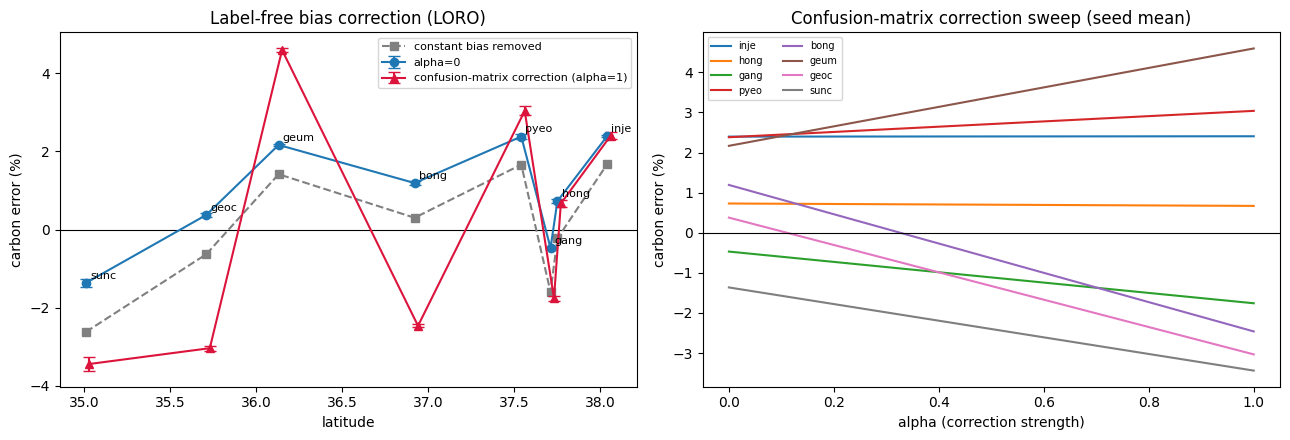

저장: exp4c_results.npz, exp4c_diag.csv, exp4c_by_region.csv, exp4c_by_seed.csv, exp4c_bias.png
→ [7]–[10] 출력과 그림을 채팅에 붙여넣기


In [24]:
# [11] 그림·저장 (영문 표기)
lat = np.array([LAT[r] for r in TRAIN_REGIONS]); o = np.argsort(lat)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].axhline(0, c='k', lw=.8)
ax[0].errorbar(lat[o], E0.mean(0)[o], yerr=E0.std(0, ddof=1)[o], fmt='o-', capsize=4, label='alpha=0')
ax[0].plot(lat[o], E_CONST.mean(0)[o], 's--', c='gray', label='constant bias removed')
ax[0].errorbar(lat[o] + .02, E_ACC.mean(0)[o], yerr=E_ACC.std(0, ddof=1)[o], fmt='^-', c='crimson', capsize=4,
               label='confusion-matrix correction (alpha=1)')
for k in o: ax[0].annotate(TRAIN_REGIONS[k][:4], (lat[k], E0.mean(0)[k]), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[0].set_xlabel('latitude'); ax[0].set_ylabel('carbon error (%)'); ax[0].legend(fontsize=8)
ax[0].set_title('Label-free bias correction (LORO)')
for j in range(nr):
    ax[1].plot(ALPHAS_REC, EA[:, j].mean(0), lw=1.5, label=TRAIN_REGIONS[j][:4])
ax[1].axhline(0, c='k', lw=.8); ax[1].set_xlabel('alpha (correction strength)'); ax[1].set_ylabel('carbon error (%)')
ax[1].set_title('Confusion-matrix correction sweep (seed mean)'); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f'{OUT}/exp4c_bias.png', dpi=150); plt.show()

DIAG.to_csv(f'{OUT}/exp4c_diag.csv')
tab.to_csv(f'{OUT}/exp4c_by_region.csv')
J.to_csv(f'{OUT}/exp4c_by_seed.csv', index=False)
print('저장: exp4c_results.npz, exp4c_diag.csv, exp4c_by_region.csv, exp4c_by_seed.csv, exp4c_bias.png')
print('→ [7]–[10] 출력과 그림을 채팅에 붙여넣기')